# Huấn luyện mô hình — nhánh DB → ML/DL → Prediction/Classification

Notebook này là nhánh trên cùng của sơ đồ trên bảng: từ **DB** (file CSV) huấn luyện các mô hình **ML/DL**
để đưa ra **xác suất nguy cơ** (prediction) và **nhãn** (classification). Kết quả được Risk Agent dùng làm công cụ.

Đầu ra (trong `ml/models/`):
- `full.sav`, `screening.sav`: mô hình phục vụ agent (mô hình gốc + bản đã hiệu chỉnh + ngưỡng)
- `metadata.json`, `metrics.csv`: thông tin làm sạch, ngưỡng, chỉ số trên tập test
- `figures/`: đường Precision-Recall và reliability diagram

Chạy lần lượt từ trên xuống (kernel **Python 3 (ISD)**). Toàn bộ mất chưa tới 1 phút.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "ml":
    os.chdir("..")              # mọi đường dẫn tính từ src/Project
sys.path.insert(0, str(Path.cwd()))

import json, subprocess, warnings
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn, xgboost
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from xgboost import XGBClassifier

from config import BASE_DIR, FIGURES_DIR, GREY_MARGIN, MODELS_DIR, RANDOM_STATE
from ml.evaluation import fit_and_evaluate
from ml.preprocess import FEATURE_SETS, SMOKING, VALID_RANGES, load_clean, split_70_15_15
import nbstyle

warnings.filterwarnings("ignore")
nbstyle.install()           # bảng có màu cố định, đọc rõ ở cả giao diện sáng lẫn tối
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## Bước 1 — Làm sạch và chia dữ liệu

- Loại **3.854 dòng trùng hoàn toàn**. Nếu để lại, cùng một bệnh nhân có thể nằm ở cả train lẫn test, làm điểm số bị thổi phồng.
- Bỏ **18 dòng `gender = Other`**, quá ít để mô hình học được.
- Giữ `smoking_history = No Info` làm một hạng mục riêng (chiếm 35,8%, không thể bỏ).
- Chia **70 / 15 / 15** có phân tầng theo nhãn, seed 42 (giống Assignment 03):
  train để học, validation để hiệu chỉnh xác suất và chọn ngưỡng, test chỉ dùng để báo cáo.

In [2]:
df, clean_stats = load_clean()
split = split_70_15_15(df)
pos_ratio = float((split.y_train == 0).sum() / (split.y_train == 1).sum())

display(pd.Series(clean_stats, dtype=object).to_frame("giá trị"))
pd.DataFrame({
    "tập": ["train", "validation", "test"],
    "số dòng": [len(split.y_train), len(split.y_val), len(split.y_test)],
    "tỉ lệ dương tính": [split.y_train.mean(), split.y_val.mean(), split.y_test.mean()],
}).round(4)

,giá trị
rows_raw,100 000
duplicates,3854
gender_other,18
rows_clean,96 128
positive_rate,0.0882


tập,số dòng,tỉ lệ dương tính
train,67 288,0.0882
validation,14 420,0.0882
test,14 420,0.0882


## Bước 2 — Hai bộ đặc trưng

| Bộ | Đặc trưng | Dùng khi |
|---|---|---|
| **full** | cả 8 cột | người dùng có kết quả HbA1c và đường huyết |
| **screening** | bỏ `HbA1c_level`, `blood_glucose_level` | chưa có xét nghiệm, chỉ sàng lọc |

HbA1c và đường huyết chính là tiêu chí chẩn đoán (xem `ml/eda.ipynb`), nên mô hình full gần như
"học lại ngưỡng chẩn đoán". Mô hình screening mới cho thấy khả năng dự đoán thật khi chưa có xét nghiệm.
Risk Agent sẽ **tự chọn** mô hình dựa trên dữ liệu người dùng cung cấp.

In [3]:
pd.DataFrame({name: pd.Series(feats) for name, feats in FEATURE_SETS.items()}).fillna("")

full,screening
gender,gender
age,age
hypertension,hypertension
heart_disease,heart_disease
smoking_history,smoking_history
bmi,bmi
HbA1c_level,
blood_glucose_level,


## Bước 3 — Các mô hình so sánh

Dữ liệu mất cân bằng (≈ 8,8% dương tính) nên mỗi mô hình đều được tăng trọng số cho lớp dương:
`class_weight="balanced"` (Logistic Regression, Random Forest) và `scale_pos_weight` (XGBoost).
MLP PyTorch (phần "DL" trên sơ đồ) dùng `pos_weight` trong hàm loss, xem `ml/mlp.py`.

In [4]:
def build_models(pos_ratio: float) -> dict:
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.9,
                                 colsample_bytree=0.9, scale_pos_weight=pos_ratio, eval_metric="aucpr",
                                 n_jobs=-1, random_state=RANDOM_STATE),
    }

## Bước 4 — Huấn luyện → hiệu chỉnh → chọn ngưỡng

Mọi mô hình đi qua cùng một hàm `fit_and_evaluate` (trong `ml/evaluation.py`):

1. Ghép **tiền xử lý** (chuẩn hóa số + one-hot) và mô hình thành một `Pipeline`, học trên **train**.
2. **Hiệu chỉnh xác suất** bằng isotonic regression trên **validation**. Tăng trọng số lớp dương làm xác suất
   bị lệch lên; agent sẽ nói với người dùng "nguy cơ 78%", nên con số này phải đúng nghĩa xác suất.
3. Chọn **ngưỡng phân loại** tối đa hóa F1 trên validation.
4. Đo trên **test**: ROC-AUC, PR-AUC, F1, Precision, Recall, Brier (sai số bình phương của xác suất).

In [5]:
nbstyle.source(fit_and_evaluate)

## Bước 5 — MLP PyTorch chạy ở tiến trình riêng

PyTorch và XGBoost mỗi bên mang một bản thư viện OpenMP (`libomp.dylib`). Nạp cả hai vào cùng một tiến trình
trên macOS gây **deadlock** (chương trình treo ở 0% CPU). Vì vậy MLP được huấn luyện trong `ml/train_mlp.py`
bằng một tiến trình con; kết quả (chỉ số + xác suất trên tập test) đọc lại từ `mlp_results.npz`.

In [6]:
def run_mlp_subprocess() -> dict:
    subprocess.run([sys.executable, "-m", "ml.train_mlp"], cwd=BASE_DIR, check=True)
    data = np.load(MODELS_DIR / "mlp_results.npz")
    summary = json.loads(str(data["summary"]))
    for set_name in summary:
        summary[set_name]["test_prob"] = data[f"{set_name}_test_prob"]
    return summary

mlp = run_mlp_subprocess()
{name: round(r["metrics"]["PR-AUC"], 4) for name, r in mlp.items()}

{'full': 0.8617, 'screening': 0.3051}

In [7]:
results = {}
for set_name, features in FEATURE_SETS.items():
    results[set_name] = {name: fit_and_evaluate(est, features, split) for name, est in build_models(pos_ratio).items()}
    results[set_name]["MLP (PyTorch)"] = mlp[set_name]
print("Đã huấn luyện xong", sum(len(v) for v in results.values()), "mô hình")

Đã huấn luyện xong 8 mô hình


## Bước 6 — Bảng kết quả trên tập test

Cột **Brier (chưa hiệu chỉnh)** cho thấy hiệu chỉnh isotonic cải thiện độ tin cậy của xác suất rõ rệt.
Dòng cuối là kết quả tốt nhất của Assignment 03 (Decision Tree, chưa loại trùng) để đối chiếu.

In [8]:
ASSIGNMENT_03_BEST = {"model": "Decision Tree (A03)", "F1": 0.8039, "ROC-AUC": 0.9731, "PR-AUC": 0.8514}

rows = []
for set_name, by_model in results.items():
    for model_name, r in by_model.items():
        rows.append({"feature_set": set_name, "model": model_name, "threshold": r["threshold"],
                     "val_PR-AUC": r["val_PR-AUC"], **r["metrics"],
                     "Brier (chưa hiệu chỉnh)": r["brier_raw"], "train_s": r["train_s"]})
table = pd.DataFrame(rows)
table.to_csv(MODELS_DIR / "metrics.csv", index=False)

show = table[["feature_set", "model", "PR-AUC", "ROC-AUC", "F1", "Recall", "Precision", "Brier", "Brier (chưa hiệu chỉnh)"]]
show = pd.concat([show, pd.DataFrame([{"feature_set": "full", **ASSIGNMENT_03_BEST}])], ignore_index=True)
show = (show.sort_values("feature_set", kind="stable")
            .rename(columns={"feature_set": "bộ đặc trưng", "model": "mô hình"})
            .set_index(["bộ đặc trưng", "mô hình"]))
caption = (f"Tập test ({len(split.y_test)} mẫu). Ô xanh: cao nhất trong từng bộ đặc trưng. "
           "Dòng A03 là kết quả Assignment 03 để đối chiếu.")
nbstyle.highlight_best(nbstyle.table(show, caption=caption), ["PR-AUC", "F1"], by="bộ đặc trưng")

## Bước 7 — Đường Precision-Recall và reliability diagram

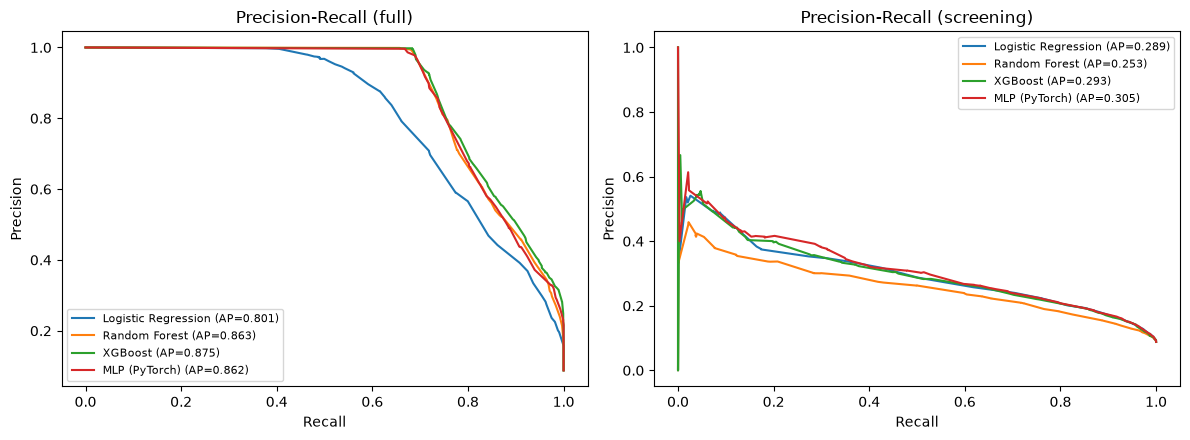

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (set_name, by_model) in zip(axes, results.items()):
    for model_name, r in by_model.items():
        precision, recall, _ = precision_recall_curve(split.y_test, r["test_prob"])
        ax.plot(recall, precision, label=f"{model_name} (AP={r['metrics']['PR-AUC']:.3f})")
    ax.set(xlabel="Recall", ylabel="Precision", title=f"Precision-Recall ({set_name})")
    ax.legend(fontsize=8)
    fig_single, ax_single = plt.subplots(figsize=(6, 5))
    for model_name, r in by_model.items():
        precision, recall, _ = precision_recall_curve(split.y_test, r["test_prob"])
        ax_single.plot(recall, precision, label=f"{model_name} (AP={r['metrics']['PR-AUC']:.3f})")
    ax_single.set(xlabel="Recall", ylabel="Precision", title=f"Precision-Recall ({set_name})")
    ax_single.legend(fontsize=8); fig_single.tight_layout()
    fig_single.savefig(FIGURES_DIR / f"pr_curve_{set_name}.png", dpi=150); plt.close(fig_single)
fig.tight_layout(); plt.show()

## Bước 8 — Chọn mô hình phục vụ agent và lưu

Risk Agent cần **giải thích** dự đoán bằng SHAP, nên chỉ chọn trong các mô hình cây (Random Forest, XGBoost),
lấy mô hình có PR-AUC cao nhất trên **validation** (không nhìn tập test khi chọn). MLP chỉ dùng để so sánh.

full       → XGBoost, ngưỡng = 0.437


screening  → XGBoost, ngưỡng = 0.227


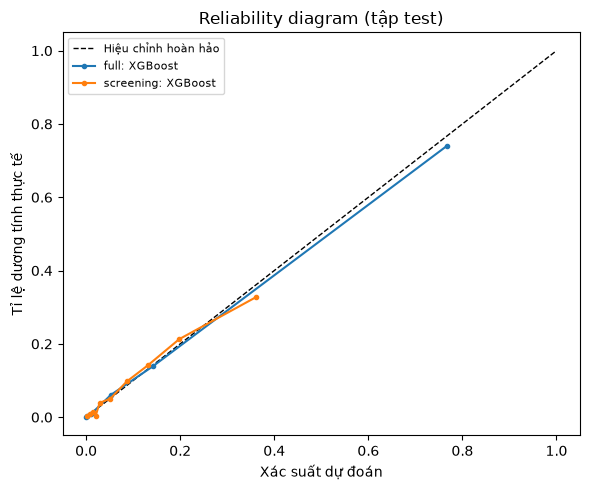

In [10]:
TREE_MODELS = ["Random Forest", "XGBoost"]
metadata_sets, reliability = {}, {}
for set_name, features in FEATURE_SETS.items():
    served_name = max(TREE_MODELS, key=lambda n: results[set_name][n]["val_PR-AUC"])
    served = results[set_name][served_name]
    joblib.dump({"base": served["base"], "calibrated": served["calibrated"], "features": features,
                 "threshold": served["threshold"], "model_name": served_name, "feature_set": set_name},
                MODELS_DIR / f"{set_name}.sav")
    metadata_sets[set_name] = {"features": features, "served_model": served_name,
                               "threshold": served["threshold"], "test_metrics": served["metrics"]}
    reliability[f"{set_name}: {served_name}"] = calibration_curve(split.y_test, served["test_prob"], n_bins=10,
                                                                  strategy="quantile")
    print(f"{set_name:10s} → {served_name}, ngưỡng = {served['threshold']:.3f}")

metadata = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "target": "diabetes",
    "cleaning": clean_stats,
    "split": {"train": len(split.y_train), "val": len(split.y_val), "test": len(split.y_test),
              "random_state": RANDOM_STATE},
    "feature_sets": metadata_sets,
    "grey_margin": GREY_MARGIN,
    "valid_ranges": VALID_RANGES,
    "smoking_categories": SMOKING,
    "assignment_03_best": ASSIGNMENT_03_BEST,
    "versions": {"sklearn": sklearn.__version__, "xgboost": xgboost.__version__},
}
(MODELS_DIR / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Hiệu chỉnh hoàn hảo")
for label, (frac, mean) in reliability.items():
    ax.plot(mean, frac, marker="o", ms=3, label=label)
ax.set(xlabel="Xác suất dự đoán", ylabel="Tỉ lệ dương tính thực tế", title="Reliability diagram (tập test)")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIGURES_DIR / "reliability.png", dpi=150); plt.show()

## Bước 9 — Thử mô hình qua `ml/predictor.py` (đúng cách Risk Agent gọi)

`predict_risk` tự chọn mô hình full/screening, `explain` trả về các đặc trưng ảnh hưởng nhiều nhất (SHAP),
`what_if` cho biết xác suất thay đổi thế nào nếu một chỉ số thay đổi.

In [11]:
import importlib, ml.predictor as predictor
importlib.reload(predictor)       # nạp lại mô hình vừa lưu
predictor.load_bundle.cache_clear(); predictor._explainer.cache_clear()

patients = {
    "Có xét nghiệm, chỉ số cao": dict(gender="Nam", age=58, bmi=33.5, hypertension=1, heart_disease=0,
                                       smoking_history="former", HbA1c_level=7.5, blood_glucose_level=220),
    "Có xét nghiệm, chỉ số bình thường": dict(gender="Nữ", age=28, bmi=21, hypertension=0, heart_disease=0,
                                               smoking_history="never", HbA1c_level=5.0, blood_glucose_level=100),
    "Chưa có xét nghiệm": dict(gender="Nữ", age=62, bmi=34, hypertension=1, heart_disease=1),
}
pd.DataFrame([{"hồ sơ": name, **{k: r[k] for k in ("model_used", "probability", "threshold", "label", "grey_zone")}}
              for name, r in ((n, predictor.predict_risk(p)) for n, p in patients.items())])

hồ sơ,model_used,probability,threshold,label,grey_zone
"Có xét nghiệm, chỉ số cao",full,0.9900,0.4368,1,✗
"Có xét nghiệm, chỉ số bình thường",full,0.0100,0.4368,0,✗
Chưa có xét nghiệm,screening,0.4596,0.2267,1,✗


In [12]:
pd.DataFrame(predictor.explain(patients["Chưa có xét nghiệm"], k=5))

feature,label,value,shap,direction
heart_disease,Bệnh tim,1,0.7206,tăng nguy cơ
age,Tuổi,62,0.6924,tăng nguy cơ
hypertension,Tăng huyết áp,1,0.5200,tăng nguy cơ
bmi,BMI,34,0.4761,tăng nguy cơ
smoking_history,Tiền sử hút thuốc,No Info,-0.2991,giảm nguy cơ


In [13]:
predictor.what_if(patients["Chưa có xét nghiệm"], {"bmi": 24})

{'ok': True,
 'changes': {'bmi': 24},
 'before': 0.4596,
 'after': 0.0981,
 'delta': -0.3615,
 'model_used': 'screening'}